# Task 2 — Disease Prediction from Medical Data
*CodeAlpha Machine Learning Internship*

**Goal:** predict whether a patient has the disease (`Outcome = 1`) from five clinical measurements:
`Glucose`, `BloodPressure`, `BMI`, `Age`, `Insulin`.

**Dataset:** 5,000 synthetic patients generated by [`generate_data.py`](generate_data.py).

> ⚠️ **Important limitation:** the label was produced by a hand-written rule. A patient is positive if **at least 3 of these 5** risk thresholds are exceeded:
> Glucose > 125, BloodPressure > 90, BMI > 30, Age > 45, Insulin > 150.
> The label has no noise and is not based on real patients. The scores below show that the workflow works, **not** that the model has clinical value.

**Which metric matters?** In screening, a **false negative** (sending a sick patient home) is usually far worse than a false positive (an extra follow-up test).
So our main metric is **recall on the positive class (sensitivity)**, with **ROC-AUC** to measure overall ranking quality.
We also report precision, so we don't "win" recall by simply flagging everyone.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score)

RANDOM_STATE = 42
CLASS_NAMES = ["No disease", "Disease"]
THRESHOLDS = {"Glucose": 125, "BloodPressure": 90, "BMI": 30, "Age": 45, "Insulin": 150}
sns.set_theme(style="whitegrid")

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/medical_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 6)


,Glucose,BloodPressure,BMI,Age,Insulin,Outcome
0,172,75,36.642935,61,181,1
1,162,83,25.851798,45,132,0
2,84,120,20.382366,48,114,0
3,176,113,27.259299,23,189,1
4,141,121,33.996298,31,173,1


In [3]:
print("Missing values per column:\n", df.isna().sum(), sep="")
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

Missing values per column:
Glucose          0
BloodPressure    0
BMI              0
Age              0
Insulin          0
Outcome          0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Glucose,5000.0,135.218200,37.789631,70.00000,102.000000,135.000000,168.000000,199.000000
BloodPressure,5000.0,99.965400,23.350967,60.00000,79.000000,100.000000,120.000000,139.000000
BMI,5000.0,29.016018,6.310335,18.00261,23.640949,29.067738,34.400679,39.995968
Age,5000.0,48.201200,17.919178,18.00000,33.000000,48.000000,64.000000,79.000000
Insulin,5000.0,142.282200,75.559137,15.00000,77.000000,140.500000,208.000000,275.000000
Outcome,5000.0,0.550400,0.497503,0.00000,0.000000,1.000000,1.000000,1.000000


## 2. Exploratory data analysis

### 2.1 Class balance

            count  share
Outcome                 
No disease   2248   0.45
Disease      2752   0.55


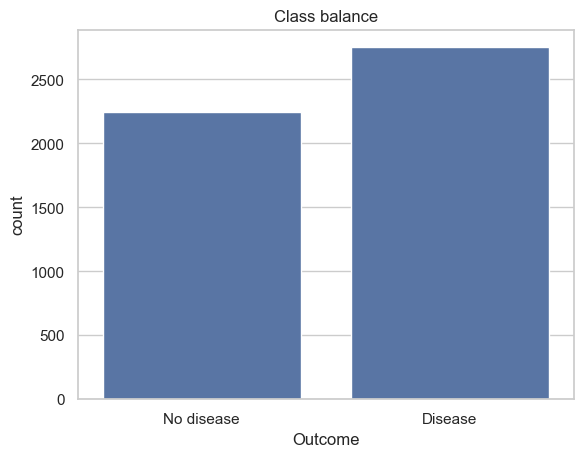

In [4]:
counts = df["Outcome"].value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share": (counts / len(df)).round(3)}).rename(index=dict(enumerate(CLASS_NAMES))))

ax = sns.countplot(x="Outcome", data=df)
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_title("Class balance")
plt.show()

### 2.2 Feature distributions by class (dashed line = risk threshold used to create the label)

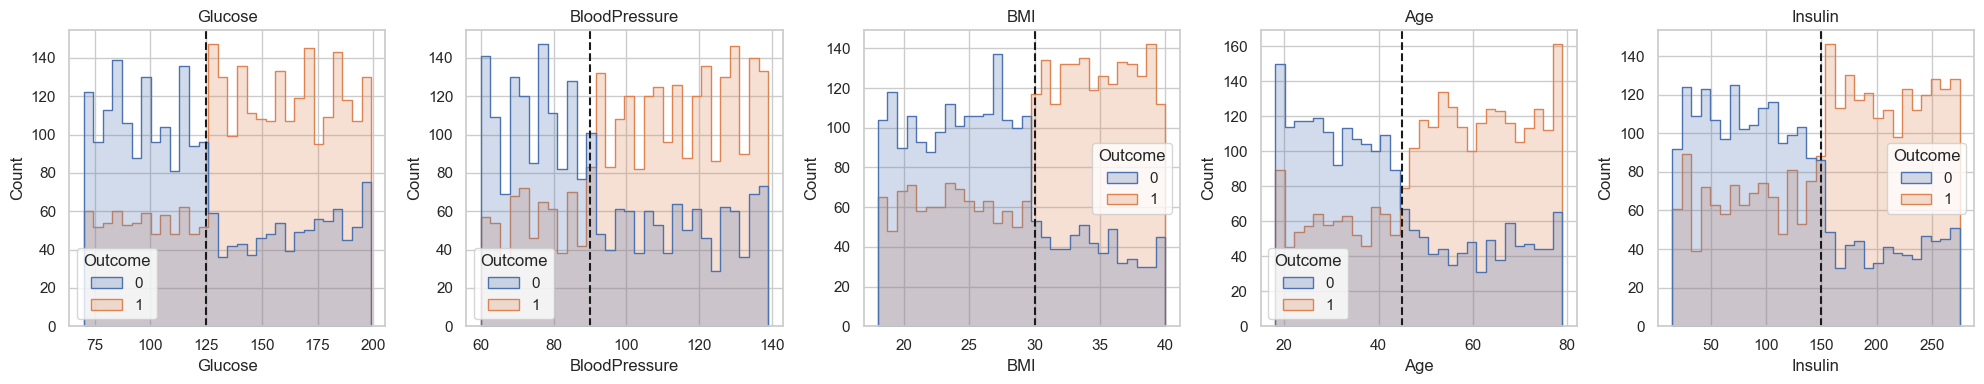

In [5]:
features = df.columns.drop("Outcome")
fig, axes = plt.subplots(1, len(features), figsize=(20, 4))
for ax, col in zip(axes, features):
    sns.histplot(data=df, x=col, hue="Outcome", bins=30, element="step", ax=ax)
    ax.axvline(THRESHOLDS[col], color="k", linestyle="--")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.3 Correlations

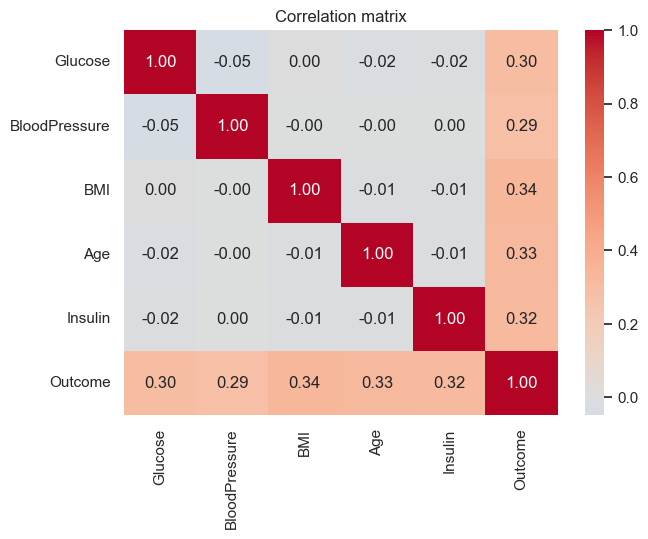

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

**Observations**
- No missing values or duplicates. Note that the features are sampled *uniformly*, so ranges like BMI 18–40 contain no
  outliers or impossible zeros. Real datasets such as Pima Diabetes have plenty of both.
- The classes are roughly balanced (~55 % positive).
- Each feature has a similar, moderate correlation with the outcome (≈ 0.3). No single feature decides the label,
  which fits the "3 out of 5 rules" design.
- In the histograms, the class mix changes **abruptly at each dashed threshold** instead of gradually.
  Models that can learn thresholds (trees) should therefore do better than a linear model.

## 3. Train / test split
We hold out a stratified 20 % test set and do not touch it until the final evaluation.

*(This is the cell that crashed in the original notebook: `X = df[[]]` selected no features and `y = df['']` selected a column that does not exist.)*

In [7]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 5)  Test: (1000, 5)


## 4. Baselines and candidate models (5-fold cross-validation)
All models are compared with stratified 5-fold cross-validation on the training set.
Scaling for logistic regression is placed inside a `Pipeline`, so it is fit on each training fold only.

| Model | Why it is included |
|---|---|
| Majority class | Lower bound: what you get without learning anything |
| Logistic Regression | The model from the original notebook; linear and interpretable |
| Decision Tree (depth ≤ 6) | Learns threshold rules, which matches how the label was made |
| Random Forest | Ensemble of trees; usually more robust than a single tree |

In [8]:
models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree (depth<=6)": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
scoring = ["accuracy", "roc_auc", "recall", "precision", "f1"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({metric: f"{scores['test_' + metric].mean():.3f} ± {scores['test_' + metric].std():.3f}"
                 for metric in scoring} | {"model": name})
cv_results = pd.DataFrame(rows).set_index("model")
cv_results

,accuracy,roc_auc,recall,precision,f1
model,,,,,
Majority class,0.551 ± 0.001,0.500 ± 0.000,1.000 ± 0.000,0.551 ± 0.001,0.710 ± 0.001
Logistic Regression,0.851 ± 0.009,0.938 ± 0.005,0.870 ± 0.013,0.861 ± 0.015,0.865 ± 0.008
Decision Tree (depth<=6),0.996 ± 0.001,0.996 ± 0.001,0.997 ± 0.002,0.997 ± 0.002,0.997 ± 0.001
Random Forest,0.998 ± 0.002,1.000 ± 0.000,0.999 ± 0.002,0.998 ± 0.002,0.998 ± 0.002


**Reading the table**
- The majority-class baseline has **recall = 1.0** because it calls *every* patient sick, but its precision is only ~0.55
  and its ROC-AUC is 0.5. This is why we never look at recall on its own.
- **Logistic Regression** is clearly better than the baseline, but it is the weakest real model. It can only draw one straight
  boundary, while the true rule counts how many thresholds are crossed.
- **Tree-based models** learn the thresholds directly and are almost perfect.

## 5. Choosing a decision threshold
By default, `predict()` labels a patient positive when the predicted probability is ≥ 0.5. For screening we might prefer
a **lower threshold** to catch more sick patients, at the cost of more false alarms.

We choose the threshold using **out-of-fold predictions on the training set** (`cross_val_predict`), **not** the test set.
Choosing it on the test set would leak test information into the model and make the final score too optimistic.

Target: **recall ≥ 0.95**, with the highest precision possible.

In [9]:
TARGET_RECALL = 0.95

def pick_threshold(model, X, y, target_recall=TARGET_RECALL):
    """Threshold <= 0.5 that reaches target_recall on out-of-fold predictions.

    We only ever *lower* the threshold: if the model already meets the target at 0.5, keep 0.5.
    """
    oof_proba = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    precision, recall, thresholds = precision_recall_curve(y, oof_proba)
    ok = recall[:-1] >= target_recall
    return min(0.5, thresholds[ok].max())

final_models = {name: models[name] for name in ["Logistic Regression", "Random Forest"]}
chosen_thresholds = {name: pick_threshold(m, X_train, y_train) for name, m in final_models.items()}
chosen_thresholds

{'Logistic Regression': np.float64(0.27353571396927073), 'Random Forest': 0.5}

## 6. Final evaluation on the held-out test set
- **Random Forest** already reaches the recall target at the default threshold, so its threshold stays at 0.5.
- For **Logistic Regression**, lowering the threshold to about 0.27 cuts missed patients sharply (67 → 26 in this run)
  but adds false alarms (83 → 138). This is the screening trade-off made explicit.

In [10]:
results = []
for name, model in final_models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    candidates = [("0.50 (default)", 0.5)]
    if chosen_thresholds[name] < 0.5:
        candidates.append((f"{chosen_thresholds[name]:.2f} (tuned)", chosen_thresholds[name]))
    for label, t in candidates:
        pred = (proba >= t).astype(int)
        results.append({"model": name, "threshold": label,
                        "recall": recall_score(y_test, pred),
                        "precision": precision_score(y_test, pred),
                        "missed patients (FN)": int(((pred == 0) & (y_test == 1)).sum()),
                        "false alarms (FP)": int(((pred == 1) & (y_test == 0)).sum()),
                        "ROC-AUC": roc_auc_score(y_test, proba)})
pd.DataFrame(results).set_index(["model", "threshold"]).round(3)

recall  precision  missed patients (FN)  \
model               threshold                                                 
Logistic Regression 0.50 (default)   0.878      0.853                    67   
                    0.27 (tuned)     0.953      0.792                    26   
Random Forest       0.50 (default)   1.000      1.000                     0   

                                    false alarms (FP)  ROC-AUC  
model               threshold                                   
Logistic Regression 0.50 (default)                 83    0.935  
                    0.27 (tuned)                  138    0.935  
Random Forest       0.50 (default)                  0    1.000

Random Forest — threshold 0.50

              precision    recall  f1-score   support

  No disease      1.000     1.000     1.000       450
     Disease      1.000     1.000     1.000       550

    accuracy                          1.000      1000
   macro avg      1.000     1.000     1.000      1000
weighted avg      1.000     1.000     1.000      1000



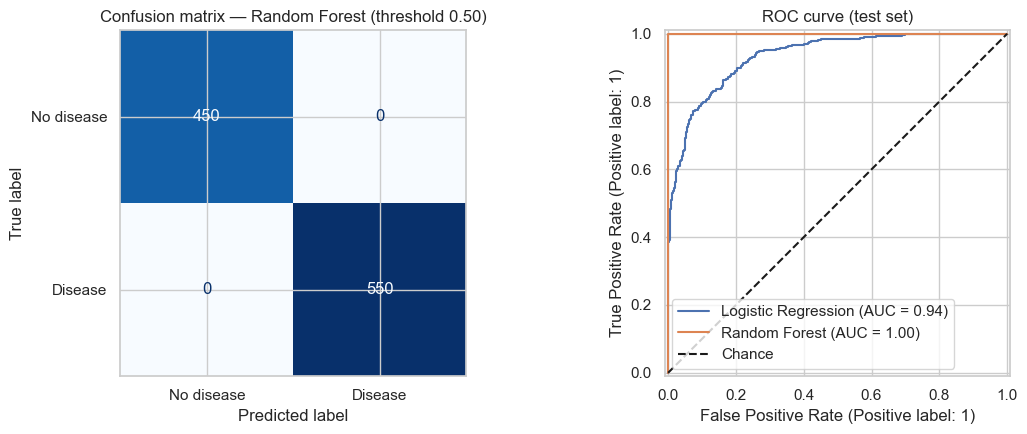

In [11]:
best = final_models["Random Forest"]
best_t = chosen_thresholds["Random Forest"]
best_pred = (best.predict_proba(X_test)[:, 1] >= best_t).astype(int)
print(f"Random Forest — threshold {best_t:.2f}\n")
print(classification_report(y_test, best_pred, target_names=CLASS_NAMES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=CLASS_NAMES).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Confusion matrix — Random Forest (threshold {best_t:.2f})")
for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].legend()
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

## 7. What did the model learn?

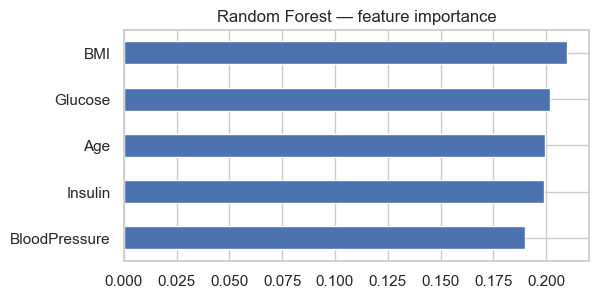

In [12]:
pd.Series(best.feature_importances_, index=features).sort_values().plot.barh(figsize=(6, 3))
plt.title("Random Forest — feature importance")
plt.show()

All five features get similar importance. This matches the labelling rule, where every risk factor counts exactly once.
On real data an uneven importance profile would be expected, and it would be worth checking with a clinician whether it makes medical sense.

## 8. Error analysis
Because we know the labelling rule, we can count how many risk thresholds each misclassified patient crosses.
The rule says 3 or more means positive.

In [13]:
test = X_test.copy()
test["actual"] = y_test
test["risk_factors"] = sum((test[col] > t).astype(int) for col, t in THRESHOLDS.items())

for name, model in final_models.items():
    pred = (model.predict_proba(X_test)[:, 1] >= chosen_thresholds[name]).astype(int)
    errors = test[pred != y_test]
    print(f"{name}: {len(errors)} errors — number of risk factors among errors:",
          errors["risk_factors"].value_counts().sort_index().to_dict())

Logistic Regression: 164 errors — number of risk factors among errors: {1: 6, 2: 132, 3: 26}
Random Forest: 0 errors — number of risk factors among errors: {}


- **Random Forest** makes no errors on this test set (100 % accuracy). This is **not** a sign of a great model. On real data, a perfect
  score is a red flag that should make you look for data leakage. Here it happens only because the label is a noise-free threshold rule
  that trees can copy exactly.
- **Logistic Regression's** errors are concentrated at **2 risk factors**, i.e. healthy patients just one factor short of the rule.
  Most of these are the extra false alarms caused by the lower threshold. A single linear boundary cannot reproduce "any 3 of 5",
  so it has to blur the cases near the rule's edge.
- On real data, the same analysis (which patients are missed?) is how you would find subgroups where the model is unsafe.

## 9. Conclusions and limitations
- **Bug fixed:** the original notebook crashed on `X = df[[]]` / `y = df['']`. It now selects the five features and `Outcome`.
- **Random Forest** is the best model here. **Logistic Regression**, the original choice, is clearly weaker because the label is
  a threshold-counting rule, not a linear one.
- **Tuning the threshold** on out-of-fold training predictions (never on the test set) lets you trade extra false alarms for fewer
  missed patients. For Logistic Regression, this cut missed patients by more than half.
- **Limitations:**
  - The labels come from a noise-free formula with uniformly sampled features, so these scores **overstate** what you can expect on real patients.
  - There is no missing data, measurement error or class imbalance. Real medical data has all three.
  - A model like this would need clinical validation and a check of calibration and fairness across groups (age, sex) before any use.
- **Next steps:** run the same pipeline on a real dataset such as Pima Indians Diabetes, UCI Heart Disease, or `sklearn.datasets.load_breast_cancer`,
  handle missing or invalid zero values, and compare with gradient boosting.